# Reading a SACC file with CMB and LSS data
This example shows how to read LSS and CMB-like data from a SACC file. You should run the `CMB_LSS_write` notebook before this one in order to have some data to read!

In [1]:
import sacc
import numpy as np
import matplotlib.pyplot as plt

## Reading the data
This is as simple as:

In [2]:
s = sacc.Sacc.load_fits('/home/hedi/HSCNG/check shear/hsc_y3_fourier_space_data_vector.sacc')

Assuming data rows are in the correct order as it was before version 1.0.


## Inspecting the contents
Let's now understand the contents of this file.

### Tracers
First, let's see what quantities have been correlated

In [3]:
for n, t in s.tracers.items():
    print(t.name, t.quantity, type(t))

wl_0 galaxy_shear <class 'sacc.tracers.nz.NZTracer'>
wl_1 galaxy_shear <class 'sacc.tracers.nz.NZTracer'>
wl_2 galaxy_shear <class 'sacc.tracers.nz.NZTracer'>
wl_3 galaxy_shear <class 'sacc.tracers.nz.NZTracer'>


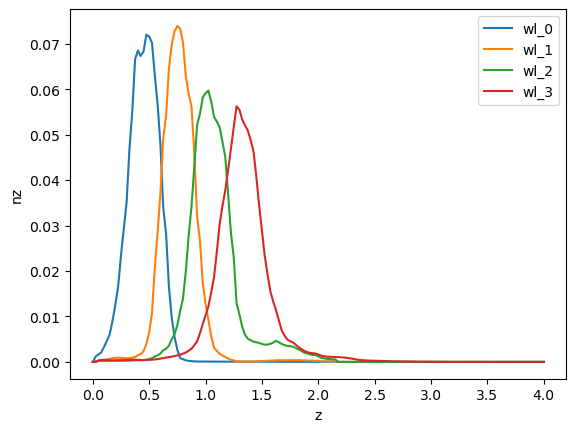

In [4]:
for i in range(4):
    plt.plot(s.tracers[f'wl_{i}'].z, s.tracers[f'wl_{i}'].nz, label=f'wl_{i}')
plt.legend()
plt.xlabel('z')
plt.ylabel('nz')
plt.show()

### Power spectra
Let's find out which two-point functions are included


In [4]:
# Type of power spectra
data_types = np.unique([d.data_type for d in s.data])
print("Data types: ", data_types)

# Tracer combinations
print("Tracer combinations: ", s.get_tracer_combinations())

# Data size
print("Size: ", s.mean.size)


Data types:  ['cl_ee']
Tracer combinations:  [('wl_0', 'wl_0'), ('wl_0', 'wl_1'), ('wl_0', 'wl_2'), ('wl_0', 'wl_3'), ('wl_1', 'wl_1'), ('wl_1', 'wl_2'), ('wl_1', 'wl_3'), ('wl_2', 'wl_2'), ('wl_2', 'wl_3'), ('wl_3', 'wl_3')]
Size:  170


### data cut
cut the large $\ell$ end

In [5]:
for t1, t2 in s.get_tracer_combinations():
    s.remove_selection(tracers=(t1, t2), ell__gt=3000)

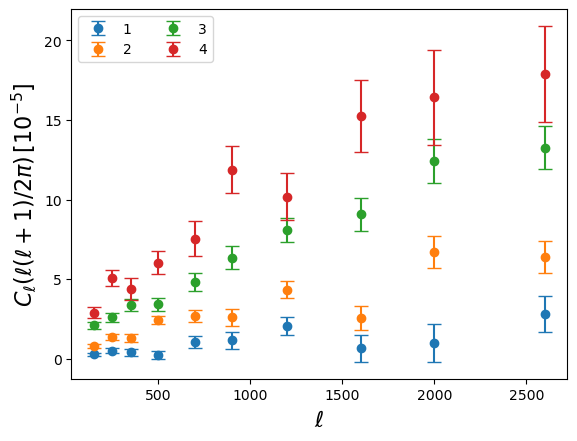

In [6]:
plt.figure()
for i in range(4):
    t1 = t2 = f'wl_{i}'
    l, cl, cov = s.get_ell_cl(None, t1, t2, return_cov=True)
    err = np.sqrt(np.diag(cov))

    y = cl * l * (l + 1) / (2 * np.pi) * 1e5
    yerr = err * l * (l + 1) / (2 * np.pi) * 1e5
    plt.errorbar(l, y, yerr, label=f'{i+1}', fmt='o', capsize=5)

plt.legend(ncol=2)
plt.xlabel(r'$\ell$', fontsize=16)
plt.ylabel(r'$C_\ell (\ell(\ell+1)/2\pi)\,[10^{-5}]$', fontsize=16)
plt.show()

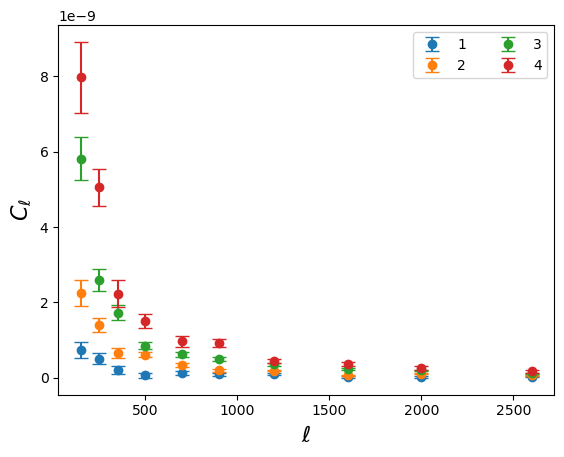

In [7]:
for i in range(4):
    t1 = t2 = f'wl_{i}'
    l, cl, cov = s.get_ell_cl(None, t1, t2, return_cov=True)
    err = np.sqrt(np.diag(cov))

    y = cl
    yerr = err
    plt.errorbar(l, y, yerr, label=f'{i+1}', fmt='o', capsize=5)


plt.legend(ncol=2)
plt.xlabel(r'$\ell$', fontsize=16)
plt.ylabel(r'$C_\ell$', fontsize=16)
plt.show()

## Bandpower window functions
Let's now access bandpower window functions. To do this, we first need to get the indices corresponding to a given power spectrum and then use `get_bandpower_windows`.

(0.0, 120.0)

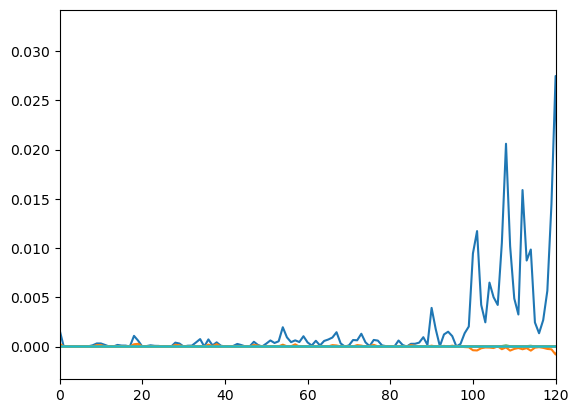

In [31]:
# Get spectra
l, cl_gg, cov_gg, ind_gg = s.get_ell_cl('cl_ee', 'wl_0', 'wl_0', return_cov=True, return_ind=True)
# Query windows from indices
bpw = s.get_bandpower_windows(ind_gg)

# Let's plot them!
plt.figure()
for w in bpw.weight.T:
    plt.plot(bpw.values, w)
plt.xlim([0, 120])

In [ ]:
from astropy.table import Table

In [23]:
tab = []
for i in range(4):
    with open(f'/home/hedi/HSCNG/check shear/shear_z{i+1}', 'r') as f:
        lines = f.readlines()
        table = Table.read(lines[:17], format='ascii')
    tab.append(table)

In [25]:
tab[0]

ls,Nl,Cl,Cl+Nl,error
float64,float64,float64,float64,float64
94.7615770047915,7.516017429522852e-10,2.748142739897363e-10,1.0264160169420215e-09,1.725335256727333e-10
129.73233490608433,7.064501242062044e-10,2.4202709074947186e-10,9.484772149556763e-10,1.196605195523114e-10
177.60868119927358,6.69307388924825e-10,3.4194526997585053e-10,1.0112526589006756e-09,8.236599608421383e-11
243.15328680533736,6.699750767474307e-10,1.444286041794151e-10,8.144036809268458e-10,5.772299204737517e-11
332.8864359839662,6.659202835806799e-10,8.361284104036079e-11,7.495331246210407e-10,4.172131807746489e-11
455.73465494966445,6.596587172727557e-10,1.6620149246221675e-11,6.762788665189774e-10,2.8914338207548595e-11
623.9187100194538,6.488792274070702e-10,3.507218719498629e-11,6.839514146020565e-10,2.0256617545733283e-11
854.1693120865127,6.32227171178879e-10,7.790474547394146e-12,6.400176457262731e-10,1.4184019499228097e-11
1169.391463973885,5.996341299587497e-10,2.054443675905729e-11,6.20178566717807e-10,9.679080854498152e-12


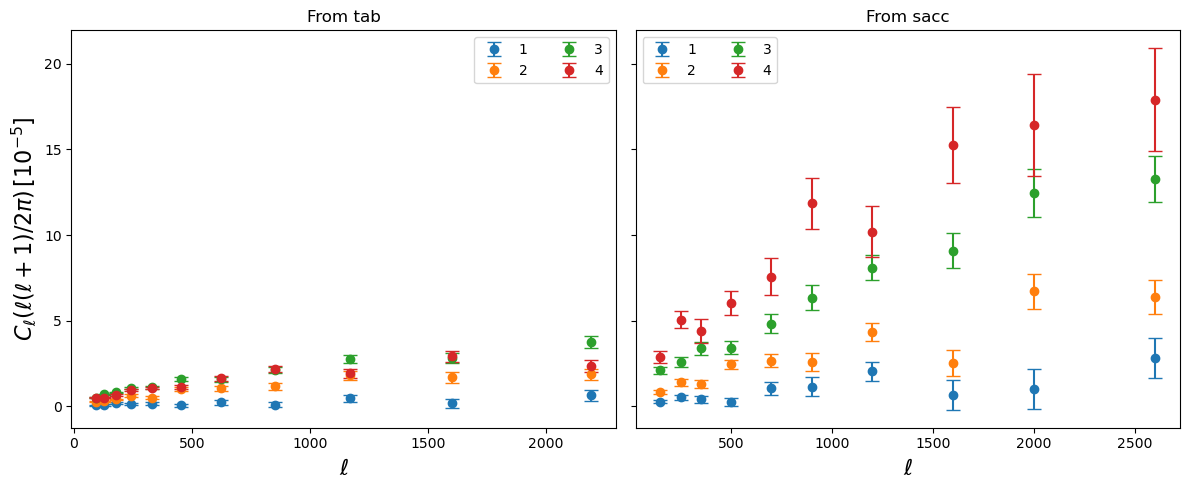

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Left: from tab
ax = axes[0]
for i in range(4):
    l = tab[i]['ls']
    cl = tab[i]['Cl']
    err = tab[i]['error']

    ind = l < 3000
    l = l[ind]
    cl = cl[ind]
    err = err[ind]

    y = cl * l * (l + 1) / (2 * np.pi) * 1e5
    yerr = err * l * (l + 1) / (2 * np.pi) * 1e5
    ax.errorbar(l, y, yerr, label=f'{i+1}', fmt='o', capsize=5)

ax.set_title('From tab')
ax.set_xlabel(r'$\ell$', fontsize=16)
ax.set_ylabel(r'$C_\ell (\ell(\ell+1)/2\pi)\,[10^{-5}]$', fontsize=16)
ax.legend(ncol=2)

# Right: from sacc
ax = axes[1]
for i in range(4):
    t1 = t2 = f'wl_{i}'
    l, cl, cov = s.get_ell_cl(None, t1, t2, return_cov=True)
    err = np.sqrt(np.diag(cov))

    y = cl * l * (l + 1) / (2 * np.pi) * 1e5
    yerr = err * l * (l + 1) / (2 * np.pi) * 1e5
    ax.errorbar(l, y, yerr, label=f'{i+1}', fmt='o', capsize=5)

ax.set_title('From sacc')
ax.set_xlabel(r'$\ell$', fontsize=16)
ax.legend(ncol=2)

plt.tight_layout()
plt.show()